# Milestone 3 – Task 6: Model Performance Comparison

## Objective

Compare the previously evaluated Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and XGBoost models for predicting Kickstarter campaign success.

**This notebook consolidates the evaluation results from Tasks 2–5. It does not train or refit any models.** Metrics and confusion matrices are recorded from the individual model notebooks. KNN's ROC-AUC is included from the updated Task 4 evaluation.

## 1. Consolidate Existing Model Results

This section consolidates the held-out test results from all four classification models: Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and XGBoost. Presenting the evaluation metrics together allows us to compare each model's performance in terms of accuracy, precision, recall, F1-score, and ROC-AUC. These complementary metrics provide insight into how effectively each model predicts Kickstarter campaign outcomes. The results are taken directly from the individual model notebooks, providing a consistent basis for comparison and further analysis. The table should be updated whenever a model's evaluation results are revised.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Recorded evaluation results from Tasks 2–5.
# No model fitting or prediction occurs in Task 6.
results = pd.DataFrame([
    {
        "Model": "Logistic Regression (with updates)",
        "Accuracy": 0.8025,
        "Precision": 0.8203,
        "Recall": 0.8185,
        "F1 Score": 0.8194,
        "ROC-AUC": 0.8804
    },
    {
        "Model": "Random Forest (Tuned)",
        "Accuracy": 0.7028,
        "Precision": 0.7024,
        "Recall": 0.7929,
        "F1 Score": 0.7449,
        "ROC-AUC": 0.7606
    },
    {
        "Model": "KNN (K=41)",
        "Accuracy": 0.6520,
        "Precision": 0.6567,
        "Recall": 0.7630,
        "F1 Score": 0.7059,
        "ROC-AUC": 0.7049
    },
    {
        "Model": "XGBoost (Tuned)",
        "Accuracy": 0.7032852876,
        "Precision": 0.7023909396,
        "Recall": 0.7945432977,
        "F1 Score": 0.7456306356,
        "ROC-AUC": 0.7670
    }
])

results_percentage = results.set_index("Model").mul(100).round(2)
results_percentage

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression (with updates),80.25,82.03,81.85,81.94,88.04
Random Forest (Tuned),70.28,70.24,79.29,74.49,76.06
KNN (K=41),65.20,65.67,76.30,70.59,70.49
XGBoost (Tuned),70.33,70.24,79.45,74.56,76.70


## 2. Compare Evaluation Metrics

Accuracy measures overall correctness; precision measures how often campaigns predicted to succeed actually succeed; recall measures how many successful campaigns are identified; F1-score balances precision and recall; and ROC-AUC measures how well the model distinguishes between successful and failed campaigns across classification thresholds.

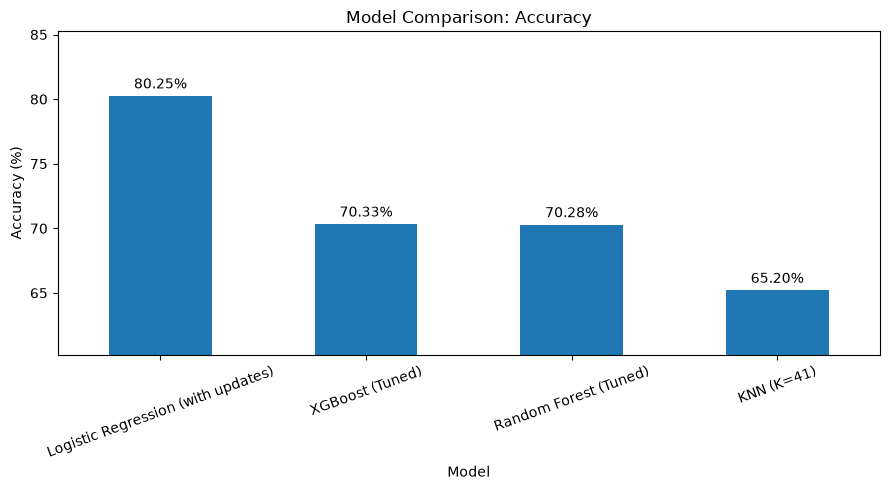

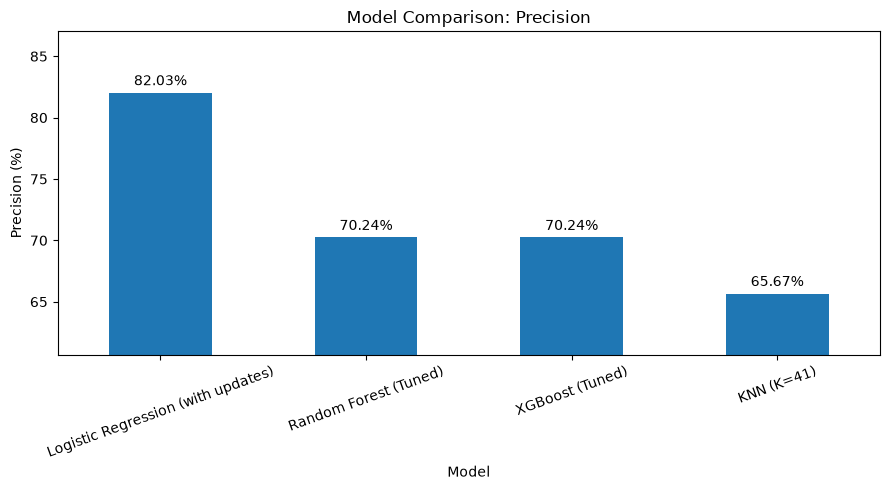

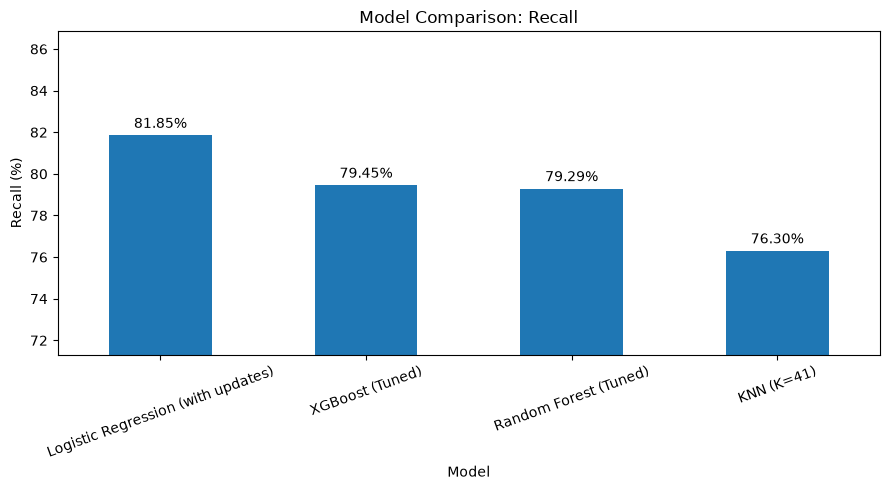

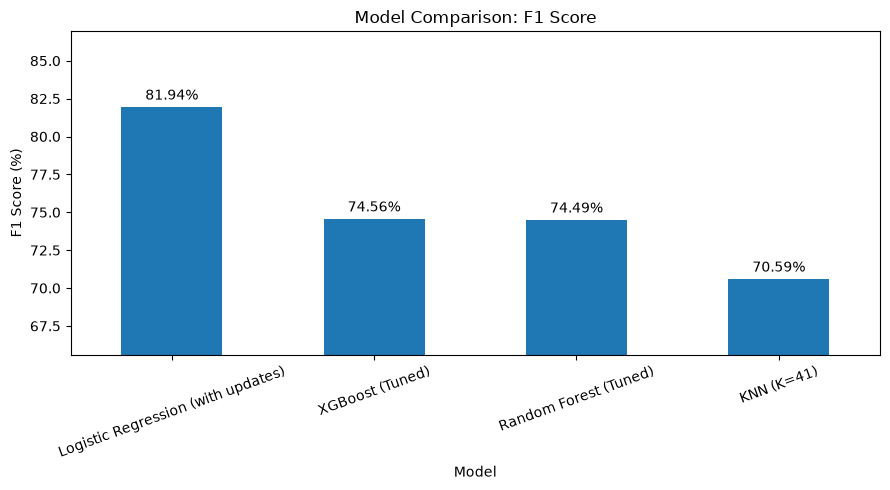

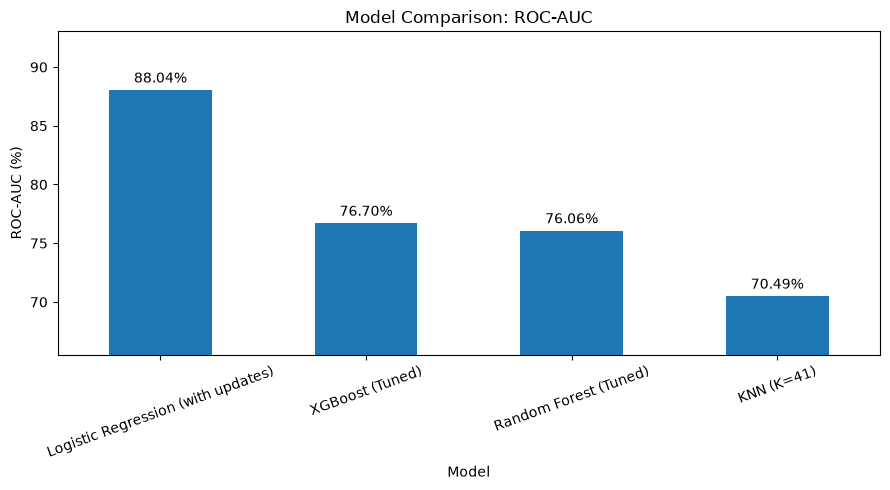

In [46]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_indexed = results.set_index("Model")

for metric in metrics_to_plot:
    values = (results_indexed[metric] * 100).sort_values(ascending=False)

    plt.figure(figsize=(9, 5))
    ax = values.plot(kind="bar", rot=20)
    plt.title(f"Model Comparison: {metric}")
    plt.ylabel(f"{metric} (%)")
    plt.ylim(max(0, values.min() - 5), min(100, values.max() + 5))
    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    plt.xlabel("Model")
    plt.tight_layout()
    plt.show()

## 3. Confusion Matrix Comparison

The matrices below are copied from the individual model evaluations. Rows represent actual outcomes and columns represent predicted outcomes. The class order is **Failed, Successful**.

- **True negative (TN):** failed campaign correctly predicted as failed.
- **False positive (FP):** failed campaign incorrectly predicted as successful.
- **False negative (FN):** successful campaign incorrectly predicted as failed.
- **True positive (TP):** successful campaign correctly predicted as successful.

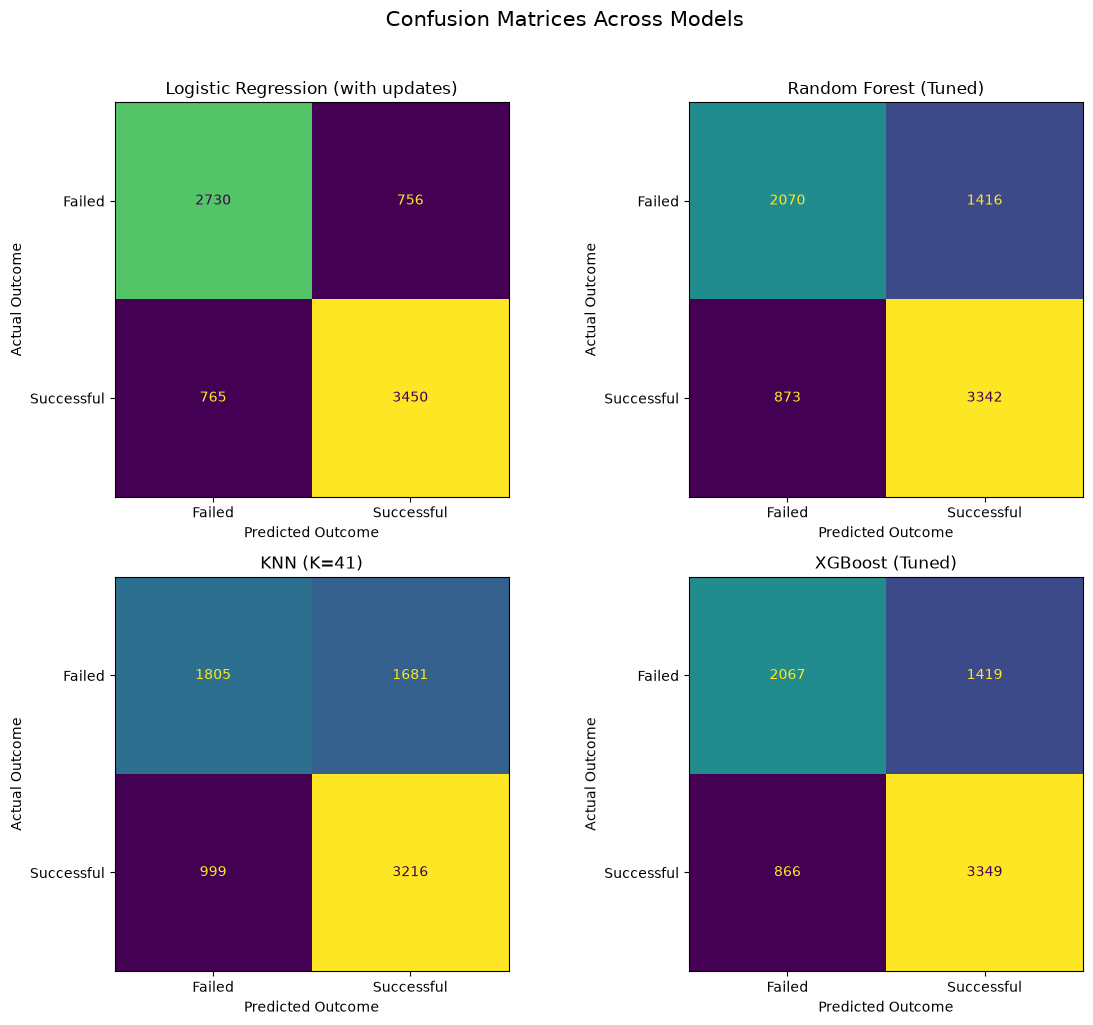

In [47]:
confusion_matrices = {
    "Logistic Regression (with updates)": np.array([[2730, 756], [765, 3450]]),
    "Random Forest (Tuned)": np.array([[2070, 1416], [873, 3342]]),
    "KNN (K=41)": np.array([[1805, 1681], [999, 3216]]),
    "XGBoost (Tuned)": np.array([[2067, 1419], [866, 3349]])
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, matrix) in zip(axes.flatten(), confusion_matrices.items()):
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Failed", "Successful"]
    )
    display.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

fig.suptitle("Confusion Matrices Across Models", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## 4. Model Performance Comparison

The four classification models—Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and XGBoost—were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Each metric provides a different perspective on predictive performance, allowing us to assess how well the models classify campaign outcomes and balance correct predictions against false positives and false negatives.

Comparing these metrics together provides a more comprehensive understanding of each model's strengths and limitations. While accuracy measures overall correctness, precision and recall evaluate the quality and coverage of positive predictions, the F1-score balances precision and recall, and ROC-AUC measures the model's ability to distinguish between the two outcome classes. These results support a more informed assessment of model performance and help identify which approaches warrant further evaluation for the project's objectives.

## 5. Best Model and Final Discussion

Based on the currently recorded results, **Logistic Regression with the updated `updates` feature set is the strongest model on the reported metrics**, achieving **80.25% accuracy**, **82.03% precision**, **81.85% recall**, **81.94% F1-score**, and **88.04% ROC-AUC**. Tuned XGBoost and Random Forest remain the next strongest models under their recorded feature setup, with ROC-AUC scores of 76.70% and 76.06%, respectively.

KNN, the model developed in Task 4, achieved 65.20% accuracy and a 70.59% F1-score. Although it identified many successful campaigns (76.30% recall), its lower accuracy, precision, and ROC-AUC indicate weaker performance than the other models in this comparison.

One consideration is that the updated Logistic Regression uses the additional `updates` feature, while the other recorded model results use the original feature set. Therefore, these results are useful for comparing the currently available model versions, but they are not a strictly like-for-like comparison of algorithms. The team should also confirm that `updates` represents information available at launch; if it reflects updates posted after launch, it could introduce data leakage for a launch-time prediction system. If the team adopts this feature set, the other models should be reevaluated with the same features before making a final model selection.